# 04 · Isothermal reactor design

Put the pieces together: a rate law, the stoichiometric table and a design equation give the volume of a
reactor - or its conversion, or the time a batch needs. This notebook designs a batch process and scales it
up, sizes a CSTR and a PFR for a second-order liquid reaction, designs a gas-phase packed bed with volume
change and pressure drop (the Ergun equation), and looks at recycle and at a membrane reactor.

**What you will learn**
- design a batch process and its cycle
- size CSTRs and PFRs for nonlinear kinetics
- include volume change and Ergun pressure drop in a packed bed
- understand recycle reactors

**Before you start:** notebooks 01-03  ·  **Time:** about 75 min

In [1]:
try:                      # on Google Colab (or anywhere engreact is missing): install it from GitHub
    import engreact
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engreact"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from engreact import ideal, kinetics, datasets
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## A batch process and its cycle time

time to 90 % conversion: 6.8 min; cycle 36.8 min; a 2 m3 batch reactor makes 14080 mol/day of product
daily output is maximised by stopping each batch at X = 0.86 (14295 mol/day); at X = 0.99 it falls to 5431 mol/day


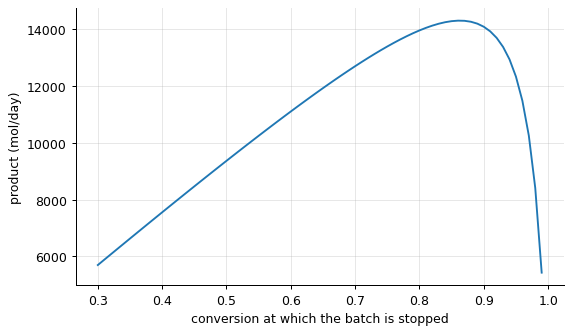

In [2]:
k2 = 0.11e-3                                                        # m3/(mol s): saponification at 25 degC (0.11 L/(mol s))
C_A0 = 200.0                                                        # mol/m3 (0.2 M, equimolar)
t_react = ideal.batch_time_nth_order(k2, C_A0, 0.9, 2)
t_cycle = t_react + 30 * 60                                         # 30 min to fill, heat, empty, clean
V = 2.0
moles_per_day = C_A0 * V * 0.9 * 86400 / t_cycle
print(f"time to 90 % conversion: {t_react/60:.1f} min; cycle {t_cycle/60:.1f} min; a 2 m3 batch reactor makes {moles_per_day:.0f} mol/day of product")
Xs = np.linspace(0.3, 0.99, 70)
daily = [C_A0 * V * X * 86400 / (ideal.batch_time_nth_order(k2, C_A0, X, 2) + 1800) for X in Xs]
X_best = Xs[int(np.argmax(daily))]
print(f"daily output is maximised by stopping each batch at X = {X_best:.2f} ({max(daily):.0f} mol/day); at X = 0.99 it falls to {daily[-1]:.0f} mol/day")
plt.plot(Xs, daily); plt.xlabel("conversion at which the batch is stopped"); plt.ylabel("product (mol/day)"); plt.show()

A second-order reaction takes as long to go from 75 % to 90 % as from 0 to 75 %: the batch time is
$X/(kC_{A0}(1-X))$, unbounded as $X \to 1$. With a fixed dead time per batch, the daily output has a maximum at
a conversion below complete - here in the high eighties, because the dead time is short compared with the
reaction; with a longer dead time the optimum moves to higher conversion, and unreacted material is recycled
either way. Batch scheduling is an optimisation, not a chemistry question.

## CSTR versus PFR for a second-order reaction

In [3]:
F_A0 = 0.5                                                          # mol/s
rate = lambda X: k2 * C_A0**2 * (1 - X) ** 2
for X in (0.5, 0.8, 0.9, 0.95):
    print(f"X = {X}: CSTR {ideal.cstr_volume(F_A0, X, rate):7.2f} m3, PFR {ideal.pfr_volume(F_A0, X, rate):6.2f} m3, ratio {ideal.cstr_volume(F_A0, X, rate)/ideal.pfr_volume(F_A0, X, rate):5.1f}")
print("\nanalytic check at X = 0.8: PFR X/(1-X) = Da ->", ideal.pfr_conversion_second_order(k2, C_A0, ideal.pfr_volume(F_A0, 0.8, rate) / (F_A0 / C_A0)))

X = 0.5: CSTR    0.23 m3, PFR   0.11 m3, ratio   2.0
X = 0.8: CSTR    2.27 m3, PFR   0.45 m3, ratio   5.0
X = 0.9: CSTR   10.23 m3, PFR   1.02 m3, ratio  10.0
X = 0.95: CSTR   43.18 m3, PFR   2.16 m3, ratio  20.0

analytic check at X = 0.8: PFR X/(1-X) = Da -> 0.8000000000000002


For second order the CSTR penalty is worse than for first: the rate falls with the square of the
concentration. At 95 % conversion the CSTR is nineteen times larger. When mixing (for heat transfer, for
slurries, for gas absorption) demands a tank, the answer is tanks in series or a PFR after the tank.

## A gas-phase packed bed with pressure drop

 u (m/s)  measured dP (Pa)  Ergun (Pa)
    0.05              76.1        75.0
    0.10             184.4       180.0
    0.20             474.6       479.0
    0.40            1411.1      1431.0
    0.80            4850.5      4752.0
    1.20           10107.0      9963.0
    1.60           17540.4     17066.0


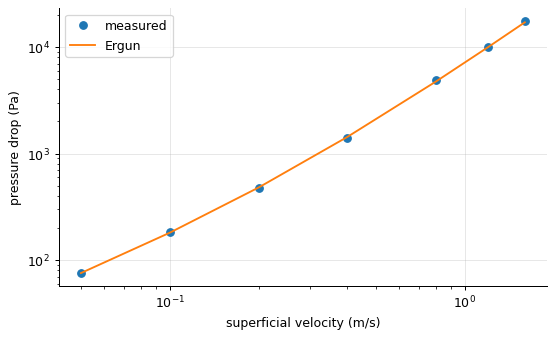

In [4]:
d = pd.read_csv(datasets.path("packed_bed_pressure_drop.csv"), comment="#")
rho, mu, Dp, phi, L = 1.15, 1.9e-5, 4e-3, 0.42, 1.5
pred = [ideal.ergun(rho * u, rho, mu, Dp, phi) * L for u in d.u_m_s]
print(pd.DataFrame({"u (m/s)": d.u_m_s, "measured dP (Pa)": d.dP_Pa, "Ergun (Pa)": np.round(pred, 0)}).to_string(index=False))
plt.loglog(d.u_m_s, d.dP_Pa, "o", label="measured"); plt.loglog(d.u_m_s, pred, label="Ergun"); plt.xlabel("superficial velocity (m/s)"); plt.ylabel("pressure drop (Pa)"); plt.legend(); plt.show()

The Ergun equation - a viscous term linear in velocity plus an inertial term quadratic in it - reproduces the
bed measurements within their scatter. Pressure drop matters for a gas-phase reaction because it lowers the
concentration downstream, and for the compressor bill.

## Conversion and pressure along the bed

alpha = 3.03e-03 1/kg -> pressure ratio at W = 100 kg without reaction: 0.835


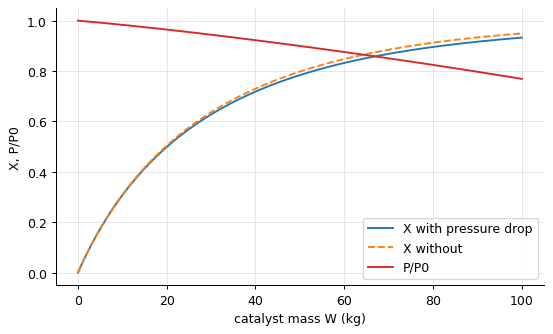

outlet: X = 0.933 with pressure drop vs 0.949 without; outlet pressure 1.54 bar


In [5]:
k_prime = 2.0e-5                                                     # m3/(kg s), first order per kg catalyst
C_A0g, eps = 40.0, 0.5                                               # A -> 1.5 products... eps = 0.5 (y_A0 = 1, delta = 0.5)
F_A0 = 0.02
alpha = ideal.ergun_alpha(beta0=ideal.ergun(rho * 0.8, rho, mu, Dp, phi), P0=2e5, A_c=0.015, rho_c=1200.0, phi=phi)
print(f"alpha = {alpha:.2e} 1/kg -> pressure ratio at W = 100 kg without reaction: {ideal.pressure_ratio_no_reaction(alpha, 100.0):.3f}")
rate_pbr = lambda X, y: k_prime * kinetics.concentration_from_conversion(C_A0g, X, eps, P_ratio=y)
pb = ideal.pbr_with_pressure_drop(F_A0, 100.0, rate_pbr, alpha, eps)
pb0 = ideal.pbr_with_pressure_drop(F_A0, 100.0, rate_pbr, 0.0, eps)
fig, ax = plt.subplots(); ax.plot(pb["W"], pb["X"], label="X with pressure drop"); ax.plot(pb0["W"], pb0["X"], "--", label="X without"); ax.plot(pb["W"], pb["y"], "C3", label="P/P0")
ax.set(xlabel="catalyst mass W (kg)", ylabel="X, P/P0"); ax.legend(); plt.show()
print(f"outlet: X = {pb['X'][-1]:.3f} with pressure drop vs {pb0['X'][-1]:.3f} without; outlet pressure {pb['y'][-1]*2:.2f} bar")

Two coupled equations along the bed: conversion rises, pressure falls (faster as the gas expands), and the
falling pressure dilutes the reactant and costs conversion. Doubling the pellet size or the tube diameter
would cut $\alpha$ - the trade-off between pressure drop and catalyst effectiveness (notebook 11) is a
central packed-bed design decision.

## Recycle

In [6]:
rate1 = lambda X: kinetics.arrhenius(5.0e7, 68e3, 320.0) * 2500.0 * (1 - X)
V = 1.0
for R in (0.0, 0.5, 2.0, 10.0, 1000.0):
    out = ideal.recycle_reactor(2.0, V, rate1, R)
    print(f"recycle ratio R = {R:6.1f}: X_out = {out['X_out']:.3f} (reactor inlet X = {out['X_in']:.3f})")
print(f"limits: PFR {ideal.pfr_conversion(2.0, V, rate1):.3f}, CSTR {ideal.cstr_conversion(2.0, V, rate1):.3f}")

recycle ratio R =    0.0: X_out = 0.392 (reactor inlet X = 0.000)
recycle ratio R =    0.5: X_out = 0.371 (reactor inlet X = 0.124)
recycle ratio R =    2.0: X_out = 0.351 (reactor inlet X = 0.234)
recycle ratio R =   10.0: X_out = 0.337 (reactor inlet X = 0.306)
recycle ratio R = 1000.0: X_out = 0.332 (reactor inlet X = 0.332)
limits: PFR 0.392, CSTR 0.332


Recycling part of the product to the inlet spans the whole range between plug flow (no recycle) and a CSTR
(infinite recycle). It costs conversion for a positive-order reaction, but it is how a tube is given the
temperature stability and the dilution of a tank - and for autocatalytic kinetics, a moderate recycle is
optimal.

## Inside the algorithm: the coupled bed equations

In [7]:
from scipy import integrate
def rhs(W, s):
    X, y = s
    return [rate_pbr(X, y) / F_A0, -alpha * (1 + eps * X) / (2 * y)]
sol = integrate.solve_ivp(rhs, (0, 100.0), [0.0, 1.0], rtol=1e-9)
print("by hand: X =", round(sol.y[0][-1], 4), "y =", round(sol.y[1][-1], 4), "; library:", round(pb["X"][-1], 4), round(pb["y"][-1], 4))

by hand: X = 0.9326 y = 0.7689 ; library: 0.9326 0.7689


## Exercises
1. The packed bed's pellets are replaced by 8 mm ones (halving the Ergun gradient at the same flow... compute it). Recompute alpha and the outlet conversion. If the reaction is diffusion-limited inside the pellets (notebook 11), what else changes?
2. A membrane reactor removes product B from A <-> B + C (K_c small) as it forms. Model it with `multiple.Network` in a PFR with an extra removal term for B (k_m C_B) and show the conversion exceeding the equilibrium value.
3. **Implement it yourself:** compute the batch cycle-time optimum: for a fixed dead time of 30 min, scan the conversion at which the batch is stopped and find the one maximising daily production for the saponification.